# Asiya's notebook

In [11]:
import io
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import librosa
import matplotlib.pyplot as plt
from datasets import load_dataset, Audio
from tqdm.auto import tqdm
from transformers import ASTFeatureExtractor, ASTForAudioClassification

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.paths import BIG_RESULTS_DIR, RESULTS_DIR, ensure_dirs

ensure_dirs()
device = "cuda" if torch.cuda.is_available() else "cpu"
SR = 16000

## Data

In [ ]:
ds = load_dataset("ashraq/esc50", split="train")
ds = ds.cast_column("audio", Audio(decode=False))

GROUPS = ["animals", "natural", "human", "domestic", "urban"]
meta = ds.remove_columns("audio").to_pandas()
meta["group"] = meta["target"].map(lambda t: GROUPS[t // 10])
meta.head()

Repo card metadata block was not found. Setting CardData to empty.


,filename,fold,target,category,esc10,src_file,take,group
0,1-100032-A-0.wav,1,0,dog,True,100032,A,animals
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A,natural
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A,domestic
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B,domestic
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A,natural


In [13]:
def load_wave(i):
    y, _ = librosa.load(io.BytesIO(ds[i]["audio"]["bytes"]), sr=SR)
    return y

meta.groupby("group")["category"].unique()

group
animals                                                                                               [dog, crow, sheep, frog, cow, insects, hen, pig, rooster, cat]
domestic    [vacuum_cleaner, door_wood_knock, can_opening, mouse_click, clock_alarm, keyboard_typing, glass_breaking, washing_machine, clock_tick, door_wood_creaks]
human                                         [clapping, footsteps, brushing_teeth, drinking_sipping, laughing, breathing, crying_baby, coughing, snoring, sneezing]
natural                                    [chirping_birds, thunderstorm, pouring_water, water_drops, wind, crackling_fire, rain, toilet_flush, sea_waves, crickets]
urban                                                            [fireworks, chainsaw, airplane, train, church_bells, car_horn, helicopter, engine, hand_saw, siren]
Name: category, dtype: object

## Model

In [14]:
CKPT = "MIT/ast-finetuned-audioset-10-10-0.4593"
fe = ASTFeatureExtractor.from_pretrained(CKPT)
model = ASTForAudioClassification.from_pretrained(CKPT).to(device).eval()
id2label = model.config.id2label

Loading weights: 100%|██████████| 203/203 [00:00<00:00, 594.43it/s]


In [15]:
@torch.no_grad()
def predict(waves):
    inputs = fe(waves, sampling_rate=SR, return_tensors="pt").to(device)
    logits = model(**inputs).logits
    # AudioSet is multi-label, so sigmoid per label, not softmax
    return torch.sigmoid(logits).cpu().numpy()

def top_k(probs, k=5):
    idx = np.argsort(probs)[::-1][:k]
    return [(id2label[int(j)], round(float(probs[j]), 3)) for j in idx]

## Single clip

In [16]:
i = 0
y = load_wave(i)
print(meta.loc[i, ["category", "group"]].to_dict())
top_k(predict([y])[0])

{'category': 'dog', 'group': 'animals'}


[('Bark', 0.199),
 ('Animal', 0.192),
 ('Dog', 0.115),
 ('Bow-wow', 0.1),
 ('Domestic animals, pets', 0.086)]

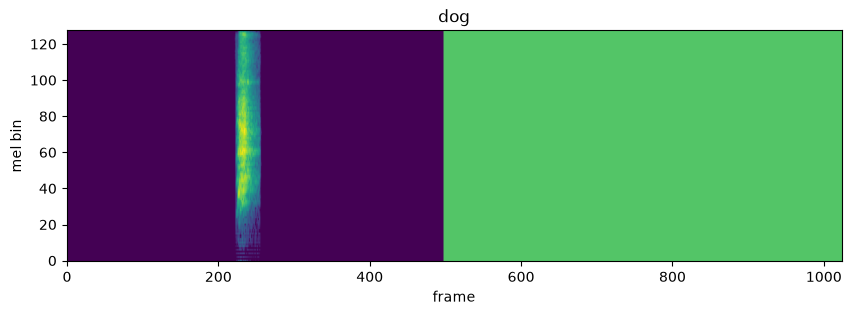

In [17]:
spec = fe(y, sampling_rate=SR, return_tensors="np")["input_values"][0]
plt.figure(figsize=(10, 3))
plt.imshow(spec.T, origin="lower", aspect="auto")
plt.title(meta.loc[i, "category"])
plt.xlabel("frame")
plt.ylabel("mel bin")
plt.show()

## Baseline on all clips

In [ ]:
CHUNK_DIR = BIG_RESULTS_DIR / "baseline_chunks"
CHUNK_DIR.mkdir(exist_ok=True)

def predict_all(chunk_size=128, batch_size=16):
    starts = range(0, len(ds), chunk_size)
    with tqdm(total=len(ds), unit="clip") as pbar:
        for start in starts:
            stop = min(start + chunk_size, len(ds))
            path = CHUNK_DIR / f"{start:04d}.npy"
            if path.exists():
                pbar.update(stop - start)
                continue
            chunk = []
            for b in range(start, stop, batch_size):
                e = min(b + batch_size, stop)
                chunk.append(predict([load_wave(j) for j in range(b, e)]))
                pbar.update(e - b)
            np.save(path, np.concatenate(chunk))
    return np.concatenate([np.load(CHUNK_DIR / f"{s:04d}.npy") for s in starts])

probs = predict_all()
np.save(BIG_RESULTS_DIR / "baseline_probs.npy", probs)
probs.shape

100%|██████████| 2000/2000 [00:00<00:00, 995680.47clip/s]


(2000, 527)

## Label mapping (AudioSet -> ESC-50)

In [23]:
probs = np.load(BIG_RESULTS_DIR / "baseline_probs.npy")
labels = np.array([id2label[i] for i in range(probs.shape[1])])

mean_by_cat = pd.DataFrame(probs, columns=labels).groupby(meta["category"]).mean()
top_labels = mean_by_cat.apply(lambda r: r.nlargest(5).round(2).to_dict(), axis=1)

pd.set_option("display.max_colwidth", None)
top_labels

category
airplane                    {'Vehicle': 0.44999998807907104, 'Aircraft': 0.27000001072883606, 'Fixed-wing aircraft, airplane': 0.18000000715255737, 'Propeller, airscrew': 0.10999999940395355, 'Eruption': 0.05999999865889549}
breathing                                                         {'Gasp': 0.4300000071525574, 'Snort': 0.4000000059604645, 'Sigh': 0.10000000149011612, 'Breathing': 0.05999999865889549, 'Sound effect': 0.019999999552965164}
brushing_teeth                                                      {'Toothbrush': 0.4699999988079071, 'Rub': 0.10999999940395355, 'Speech': 0.05000000074505806, 'Animal': 0.03999999910593033, 'Scratch': 0.03999999910593033}
can_opening            {'Cap gun': 0.10999999940395355, 'Gunshot, gunfire': 0.07999999821186066, 'Single-lens reflex camera': 0.05000000074505806, 'Finger snapping': 0.05000000074505806, 'Sound effect': 0.029999999329447746}
car_horn                       {'Vehicle': 0.4000000059604645, 'Vehicle horn, car horn, hon

In [ ]:
from src.esc import prediction_table
from src.label_map import ESC_TO_AUDIOSET

table, scores = prediction_table(probs, labels, meta["target"])
pred = pd.concat([meta[["filename", "fold", "target", "category", "group"]], table], axis=1)
pred["mappable"] = pred["category"].map(lambda c: bool(ESC_TO_AUDIOSET[c]))

In [ ]:
pred.to_csv(RESULTS_DIR / "baseline_predictions.csv", index=False)
np.save(BIG_RESULTS_DIR / "baseline_scores_esc.npy", scores)

print("accuracy:", round(pred["correct"].mean(), 3), "| mappable only:", round(pred.loc[pred["mappable"], "correct"].mean(), 3))
pred.groupby("group")["correct"].mean().round(2)

## First look at errors

In [26]:
err = pred[~pred["correct"]]
err.groupby(["category", "pred"]).size().sort_values(ascending=False).head(20)

category          pred           
pouring_water     water_drops        29
washing_machine   engine             27
mouse_click       keyboard_typing    19
drinking_sipping  water_drops        18
can_opening       glass_breaking     15
vacuum_cleaner    airplane           12
mouse_click       clock_tick         11
chainsaw          engine             11
wind              sea_waves           8
airplane          engine              7
helicopter        engine              7
drinking_sipping  breathing           7
sneezing          coughing            7
                  breathing           7
snoring           breathing           7
can_opening       crackling_fire      6
crackling_fire    rain                5
wind              train               5
                  engine              5
                  siren               5
dtype: int64

In [27]:
# "Animal" is the AudioSet parent node; p_animal_max is the best score over all animal labels
pred.groupby("group")[["p_animal_parent", "p_animal_max"]].mean().round(2)

,p_animal_parent,p_animal_max
group,,
animals,0.21,0.74
domestic,0.00,0.01
human,0.01,0.02
natural,0.02,0.09
urban,0.01,0.01
